In [ ]:

# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("LearnSphere Marketing Analysis")
print("Python environment is ready!")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


LearnSphere Marketing Analysis
Python environment is ready!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [ ]:

# STEP 2: Create our project data structure

datasets = {
    "Campaign": [
        "campaign_id", "channel", "start_date",
        "end_date", "daily_budget", "target_audience"
    ],

    "Performance": [
        "date", "campaign_id", "impressions",
        "clicks", "spend"
    ],

    "Lead": [
        "lead_id", "lead_date", "campaign_id",
        "city", "age_group", "course_interest"
    ],

    "Sales": [
        "lead_id", "counsellor_id", "call_attempts",
        "demo_attended", "lead_status"
    ],

    "Enrolment": [
        "lead_id", "enrolment_date", "course",
        "fee_paid", "discount", "refund"
    ]
}

for table, columns in datasets.items():
    print("\n", table)
    print("Columns:", columns)

print("\nAll five dataset structures are ready!")



 Campaign
Columns: ['campaign_id', 'channel', 'start_date', 'end_date', 'daily_budget', 'target_audience']

 Performance
Columns: ['date', 'campaign_id', 'impressions', 'clicks', 'spend']

 Lead
Columns: ['lead_id', 'lead_date', 'campaign_id', 'city', 'age_group', 'course_interest']

 Sales
Columns: ['lead_id', 'counsellor_id', 'call_attempts', 'demo_attended', 'lead_status']

 Enrolment
Columns: ['lead_id', 'enrolment_date', 'course', 'fee_paid', 'discount', 'refund']

All five dataset structures are ready!


In [3]:

# STEP 2: Load the actual hackathon dataset

import pandas as pd

file_path = "/content/9853.xlsx"

# Read all five sheets
campaign_df = pd.read_excel(file_path, sheet_name="Campaign")
performance_df = pd.read_excel(file_path, sheet_name="Performance")
lead_df = pd.read_excel(file_path, sheet_name="Lead")
sales_df = pd.read_excel(file_path, sheet_name="Sales")
enrolment_df = pd.read_excel(file_path, sheet_name="Enrolment")

# Display dataset sizes
print("CAMPAIGN:", campaign_df.shape)
print("PERFORMANCE:", performance_df.shape)
print("LEAD:", lead_df.shape)
print("SALES:", sales_df.shape)
print("ENROLMENT:", enrolment_df.shape)

print("\nAll five datasets loaded successfully!")


CAMPAIGN: (100, 6)
PERFORMANCE: (100, 5)
LEAD: (100, 6)
SALES: (100, 5)
ENROLMENT: (50, 6)

All five datasets loaded successfully!


In [4]:

# STEP 3: DATA QUALITY CHECK

# Store all datasets together
all_data = {
    "Campaign": campaign_df,
    "Performance": performance_df,
    "Lead": lead_df,
    "Sales": sales_df,
    "Enrolment": enrolment_df
}

# Check every dataset
for name, df in all_data.items():

    print("\n" + "=" * 50)
    print("DATASET:", name)
    print("=" * 50)

    # Number of rows and columns
    print("Shape:", df.shape)

    # Missing values
    print("\nMissing values:")
    print(df.isnull().sum())

    # Duplicate records
    print("\nDuplicate rows:", df.duplicated().sum())

    # Data types
    print("\nColumn data types:")
    print(df.dtypes)

print("\nDATA QUALITY CHECK COMPLETED!")



DATASET: Campaign
Shape: (100, 6)

Missing values:
campaign_id        0
channel            0
start_date         0
end_date           0
daily_budget       0
target_audience    0
dtype: int64

Duplicate rows: 0

Column data types:
campaign_id                object
channel                    object
start_date         datetime64[ns]
end_date           datetime64[ns]
daily_budget                int64
target_audience            object
dtype: object

DATASET: Performance
Shape: (100, 5)

Missing values:
campaign_id    0
date           0
impressions    0
clicks         0
spend          0
dtype: int64

Duplicate rows: 0

Column data types:
campaign_id            object
date           datetime64[ns]
impressions             int64
clicks                  int64
spend                 float64
dtype: object

DATASET: Lead
Shape: (100, 6)

Missing values:
lead_id            0
lead_date          0
campaign_id        0
city               0
age_group          0
course_interest    0
dtype: int64

Duplicat

In [5]:

# STEP 4: VALIDATE DATA RELATIONSHIPS

print("========== RELATIONSHIP VALIDATION ==========")

# 1. Check duplicate primary IDs
print("\n1. DUPLICATE IDs")

print("Campaign IDs:",
      campaign_df["campaign_id"].duplicated().sum())

print("Lead IDs:",
      lead_df["lead_id"].duplicated().sum())

# 2. Check whether lead campaigns exist
valid_campaigns = set(campaign_df["campaign_id"])

invalid_lead_campaigns = (
    set(lead_df["campaign_id"]) - valid_campaigns
)

print("\n2. INVALID CAMPAIGN REFERENCES")
print("Leads with invalid campaigns:",
      len(invalid_lead_campaigns))

# 3. Check performance campaign references
invalid_performance_campaigns = (
    set(performance_df["campaign_id"]) - valid_campaigns
)

print("Performance records with invalid campaigns:",
      len(invalid_performance_campaigns))

# 4. Check sales lead references
valid_leads = set(lead_df["lead_id"])

invalid_sales_leads = (
    set(sales_df["lead_id"]) - valid_leads
)

print("\n3. INVALID SALES REFERENCES")
print("Sales records with invalid leads:",
      len(invalid_sales_leads))

# 5. Check enrolment lead references
invalid_enrolment_leads = (
    set(enrolment_df["lead_id"]) - valid_leads
)

print("\n4. INVALID ENROLMENT REFERENCES")
print("Enrolments with invalid leads:",
      len(invalid_enrolment_leads))

print("\nRELATIONSHIP VALIDATION COMPLETED!")


========== RELATIONSHIP VALIDATION ==========

1. DUPLICATE IDs
Campaign IDs: 0
Lead IDs: 0

2. INVALID CAMPAIGN REFERENCES
Leads with invalid campaigns: 0
Performance records with invalid campaigns: 0

3. INVALID SALES REFERENCES
Sales records with invalid leads: 0

4. INVALID ENROLMENT REFERENCES
Enrolments with invalid leads: 0

RELATIONSHIP VALIDATION COMPLETED!


In [6]:

# STEP 5: BUSINESS KPI ANALYSIS

# 1. Total marketing spend
total_spend = performance_df["spend"].sum()

# 2. Total impressions and clicks
total_impressions = performance_df["impressions"].sum()
total_clicks = performance_df["clicks"].sum()

# 3. Total leads
total_leads = lead_df["lead_id"].nunique()

# 4. Total enrolments
total_enrolments = enrolment_df["lead_id"].nunique()

# 5. Refund analysis
refund_yes = enrolment_df["refund"].astype(str).str.strip().str.lower() == "yes"

refunded_enrolments = enrolment_df.loc[refund_yes, "lead_id"].nunique()

# 6. Retained students (non-refunded)
retained_df = enrolment_df.loc[~refund_yes]

retained_students = retained_df["lead_id"].nunique()

# 7. Revenue calculations
gross_revenue = enrolment_df["fee_paid"].sum()
net_revenue_proxy = retained_df["fee_paid"].sum()

# 8. Marketing KPIs
cost_per_lead = total_spend / total_leads

cac_all = total_spend / total_enrolments

cac_retained = (
    total_spend / retained_students
    if retained_students > 0 else 0
)

conversion_rate = (total_enrolments / total_leads) * 100

ctr = (total_clicks / total_impressions) * 100

roas = net_revenue_proxy / total_spend

# 9. Display results
print("========== LEARNSPHERE KPI REPORT ==========")

print(f"Total Spend: ₹{total_spend:,.2f}")
print(f"Total Impressions: {total_impressions:,}")
print(f"Total Clicks: {total_clicks:,}")
print(f"Total Leads: {total_leads}")
print(f"Total Enrolments: {total_enrolments}")
print(f"Refunded Students: {refunded_enrolments}")
print(f"Retained Students: {retained_students}")

print("\n========== MARKETING KPIs ==========")

print(f"Cost Per Lead: ₹{cost_per_lead:,.2f}")
print(f"CAC (All Enrolments): ₹{cac_all:,.2f}")
print(f"CAC (Non-refunded): ₹{cac_retained:,.2f}")
print(f"Lead to Enrolment: {conversion_rate:.2f}%")
print(f"Click Through Rate: {ctr:.2f}%")
print(f"Gross Fee Paid: ₹{gross_revenue:,.2f}")
print(f"Revenue excluding refunds: ₹{net_revenue_proxy:,.2f}")
print(f"Net Revenue ROAS: {roas:.2f}x")

print("\nKPI ANALYSIS COMPLETED!")


========== LEARNSPHERE KPI REPORT ==========
Total Spend: ₹121,762.22
Total Impressions: 1,443,732
Total Clicks: 154,070
Total Leads: 100
Total Enrolments: 50
Refunded Students: 10
Retained Students: 40

========== MARKETING KPIs ==========
Cost Per Lead: ₹1,217.62
CAC (All Enrolments): ₹2,435.24
CAC (Non-refunded): ₹3,044.06
Lead to Enrolment: 50.00%
Click Through Rate: 10.67%
Gross Fee Paid: ₹1,857,266.92
Revenue excluding refunds: ₹1,474,247.01
Net Revenue ROAS: 12.11x

KPI ANALYSIS COMPLETED!


In [7]:

# STEP 6: CHANNEL-WISE MARKETING ANALYSIS

# Connect campaign information with advertising performance
channel_performance = campaign_df[
    ["campaign_id", "channel"]
].merge(
    performance_df,
    on="campaign_id",
    how="left"
)

# Connect leads with their advertising channels
channel_leads = lead_df.merge(
    campaign_df[["campaign_id", "channel"]],
    on="campaign_id",
    how="left"
)

# Connect enrolments to their original marketing channels
channel_enrolments = enrolment_df.merge(
    lead_df[["lead_id", "campaign_id"]],
    on="lead_id",
    how="left"
).merge(
    campaign_df[["campaign_id", "channel"]],
    on="campaign_id",
    how="left"
)

# Calculate advertising performance by channel
spend_summary = channel_performance.groupby("channel").agg(
    total_spend=("spend", "sum"),
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum")
)

# Calculate leads by channel
lead_summary = channel_leads.groupby("channel").agg(
    total_leads=("lead_id", "nunique")
)

# Calculate enrolments and revenue by channel
enrolment_summary = channel_enrolments.groupby("channel").agg(
    total_enrolments=("lead_id", "nunique"),
    revenue=("fee_paid", "sum")
)

# Combine all summaries
channel_analysis = (
    spend_summary
    .join(lead_summary)
    .join(enrolment_summary)
)

# Calculate KPIs
channel_analysis["CPL"] = (
    channel_analysis["total_spend"] /
    channel_analysis["total_leads"]
)

channel_analysis["CAC"] = (
    channel_analysis["total_spend"] /
    channel_analysis["total_enrolments"]
)

channel_analysis["Conversion_Rate"] = (
    channel_analysis["total_enrolments"] /
    channel_analysis["total_leads"]
) * 100

channel_analysis["CTR"] = (
    channel_analysis["clicks"] /
    channel_analysis["impressions"]
) * 100

channel_analysis["ROAS"] = (
    channel_analysis["revenue"] /
    channel_analysis["total_spend"]
)

# Display results
print("========== CHANNEL PERFORMANCE ==========")

display(channel_analysis.round(2))

print("\nCHANNEL ANALYSIS COMPLETED!")


========== CHANNEL PERFORMANCE ==========


,total_spend,impressions,clicks,total_leads,total_enrolments,revenue,CPL,CAC,Conversion_Rate,CTR,ROAS
channel,,,,,,,,,,,
Facebook,30053.12,330595,36757,22,13,517942.19,1366.05,2311.78,59.09,11.12,17.23
Google Ads,26182.91,265902,28666,17,9,280141.30,1540.17,2909.21,52.94,10.78,10.70
Instagram,29328.86,405431,42737,32,18,653860.48,916.53,1629.38,56.25,10.54,22.29
WhatsApp,15716.01,229620,27811,13,3,129304.81,1208.92,5238.67,23.08,12.11,8.23
YouTube,20481.32,212184,18099,16,7,276018.14,1280.08,2925.90,43.75,8.53,13.48



CHANNEL ANALYSIS COMPLETED!
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


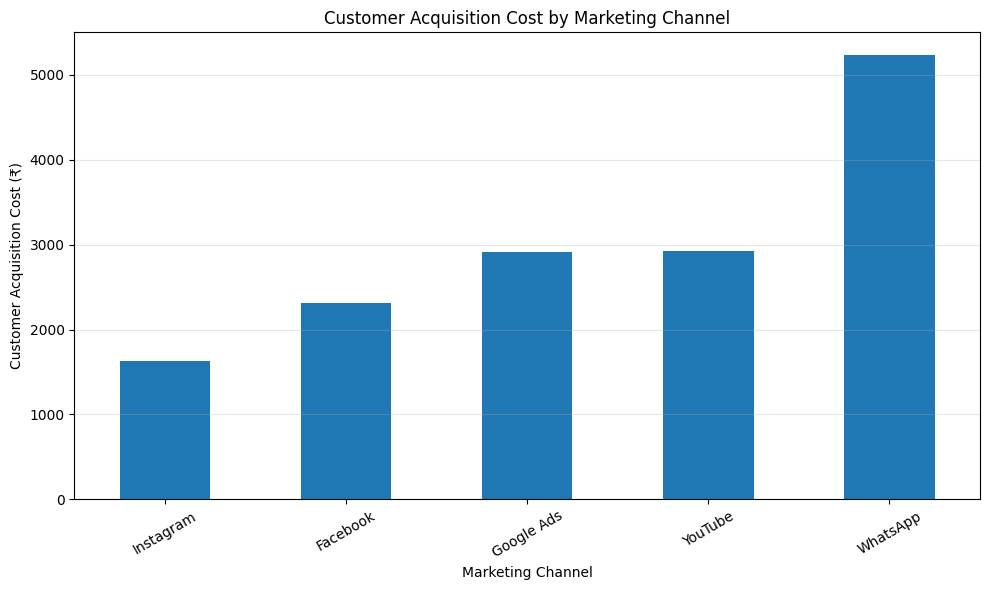

In [8]:

# STEP 7: CUSTOMER ACQUISITION COST CHART

plt.figure(figsize=(10, 6))

channel_analysis["CAC"].sort_values().plot(
    kind="bar",
    title="Customer Acquisition Cost by Marketing Channel"
)

plt.xlabel("Marketing Channel")
plt.ylabel("Customer Acquisition Cost (₹)")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


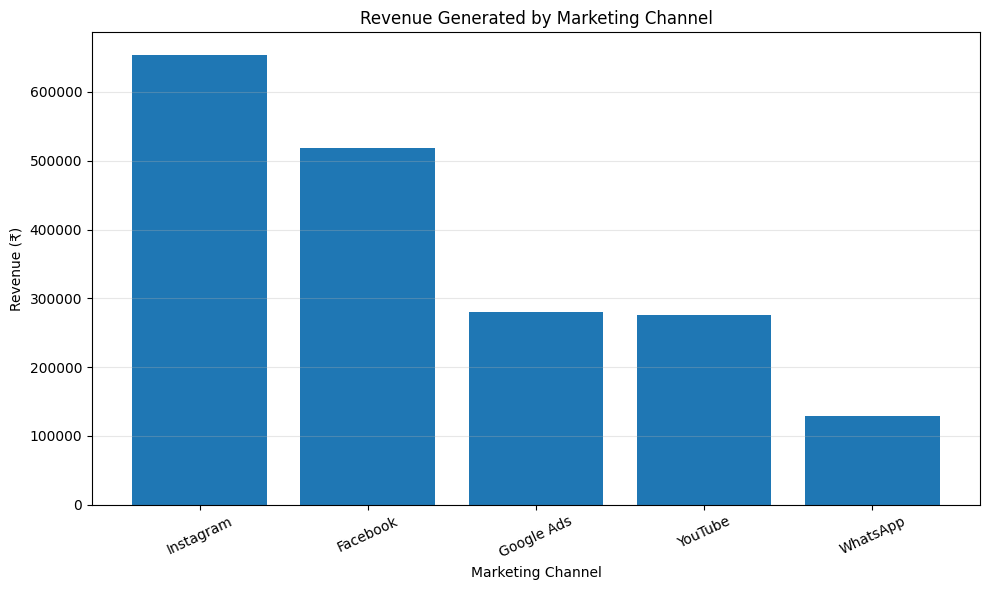

REVENUE RANKING


,revenue,total_enrolments,ROAS
channel,,,
Instagram,653860.48,18,22.29
Facebook,517942.19,13,17.23
Google Ads,280141.30,9,10.70
YouTube,276018.14,7,13.48
WhatsApp,129304.81,3,8.23


In [10]:

# STEP 8: REVENUE BY MARKETING CHANNEL

# Sort channels by revenue
revenue_data = channel_analysis.sort_values(
    by="revenue",
    ascending=False
)

# Create revenue chart
plt.figure(figsize=(10, 6))

plt.bar(
    revenue_data.index,
    revenue_data["revenue"]
)

plt.title("Revenue Generated by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Revenue (₹)")

plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Display revenue ranking
print("REVENUE RANKING")
display(revenue_data[["revenue", "total_enrolments", "ROAS"]].round(2))


========== SALES FUNNEL ==========


,Stage,Count,Conversion_Percent,Dropoff_Percent
0,Impressions,1443732,100.00,0.00
1,Clicks,154070,10.67,89.33
2,Leads,100,0.06,99.94
3,Demos Attended,62,62.00,38.00
4,Paid Enrolments,50,80.65,19.35


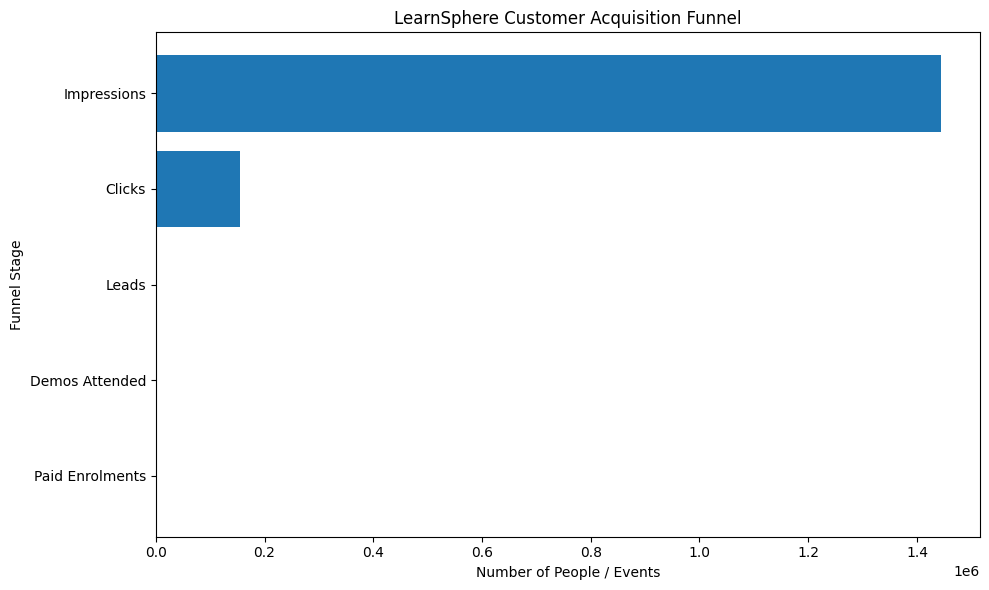

SALES FUNNEL ANALYSIS COMPLETED!


In [11]:

# STEP 9: SALES FUNNEL ANALYSIS

# Count impressions and clicks
impressions = performance_df["impressions"].sum()
clicks = performance_df["clicks"].sum()

# Count leads
leads = lead_df["lead_id"].nunique()

# Count demos attended
demo_yes = (
    sales_df["demo_attended"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["yes", "true", "1"])
)

demos = sales_df.loc[demo_yes, "lead_id"].nunique()

# Count paid enrolments
enrolments = enrolment_df["lead_id"].nunique()

# Create funnel table
funnel = pd.DataFrame({
    "Stage": [
        "Impressions",
        "Clicks",
        "Leads",
        "Demos Attended",
        "Paid Enrolments"
    ],
    "Count": [
        impressions,
        clicks,
        leads,
        demos,
        enrolments
    ]
})

# Calculate conversion from previous stage
funnel["Conversion_Percent"] = (
    funnel["Count"] / funnel["Count"].shift(1) * 100
)

funnel["Dropoff_Percent"] = (
    100 - funnel["Conversion_Percent"]
)

funnel.loc[0, "Conversion_Percent"] = 100
funnel.loc[0, "Dropoff_Percent"] = 0

print("========== SALES FUNNEL ==========")
display(funnel.round(2))

# Plot funnel
plt.figure(figsize=(10, 6))

plt.barh(
    funnel["Stage"],
    funnel["Count"]
)

plt.title("LearnSphere Customer Acquisition Funnel")
plt.xlabel("Number of People / Events")
plt.ylabel("Funnel Stage")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("SALES FUNNEL ANALYSIS COMPLETED!")


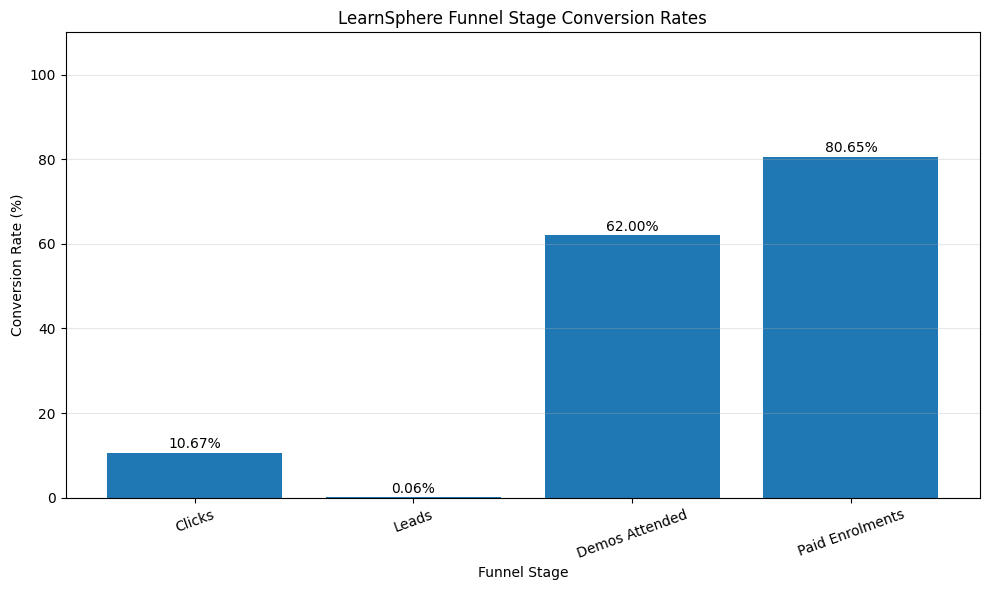

In [12]:

# STEP 9.2: FUNNEL CONVERSION VISUALIZATION

conversion_data = funnel.iloc[1:].copy()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    conversion_data["Stage"],
    conversion_data["Conversion_Percent"]
)

# Add percentage labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.title("LearnSphere Funnel Stage Conversion Rates")
plt.xlabel("Funnel Stage")
plt.ylabel("Conversion Rate (%)")

plt.ylim(0, 110)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


========== COURSE PERFORMANCE ==========


,total_enrolments,total_revenue,average_fee,total_discount,refunded_students
course,,,,,
Digital Marketing,12,533653.58,44471.13,58160.66,3.0
Full Stack Development,13,448038.25,34464.48,49370.92,5.0
Data Analytics,9,340220.77,37802.31,46635.03,0.0
Python Programming,11,327145.93,29740.54,39701.54,2.0
Web Development,5,208208.39,41641.68,16179.98,0.0


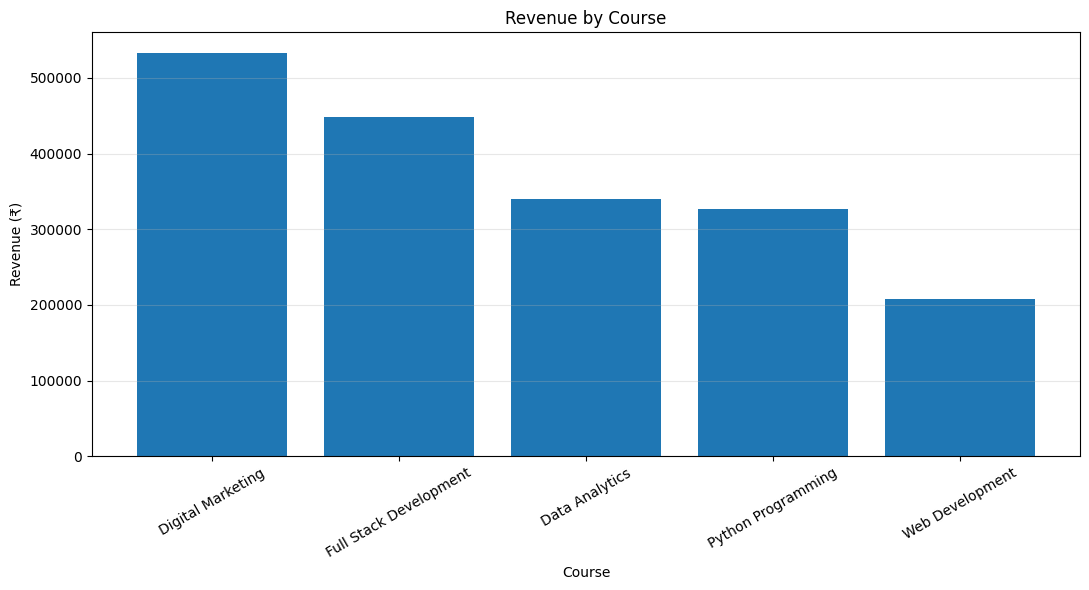

COURSE ANALYSIS COMPLETED!


In [13]:

# STEP 10: COURSE-WISE PERFORMANCE ANALYSIS

# Group enrolments by course
course_analysis = enrolment_df.groupby("course").agg(
    total_enrolments=("lead_id", "nunique"),
    total_revenue=("fee_paid", "sum"),
    average_fee=("fee_paid", "mean"),
    total_discount=("discount", "sum")
)

# Calculate refunded records
refund_flag = (
    enrolment_df["refund"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["yes", "true", "1"])
)

refund_data = enrolment_df[refund_flag].groupby("course").agg(
    refunded_students=("lead_id", "nunique")
)

# Combine results
course_analysis = course_analysis.join(
    refund_data
).fillna(0)

# Sort by revenue
course_analysis = course_analysis.sort_values(
    by="total_revenue",
    ascending=False
)

# Display results
print("========== COURSE PERFORMANCE ==========")

display(course_analysis.round(2))

# Revenue chart
plt.figure(figsize=(11, 6))

plt.bar(
    course_analysis.index.astype(str),
    course_analysis["total_revenue"]
)

plt.title("Revenue by Course")
plt.xlabel("Course")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("COURSE ANALYSIS COMPLETED!")


========== COUNSELLOR PERFORMANCE ==========


,leads_handled,total_calls,average_calls,demos_attended,enrolled_students,revenue,Demo_Rate,Conversion_Rate
counsellor_id,,,,,,,,
CN004,6,27,4.50,5,4,169557.39,83.33,66.67
CN006,5,21,4.20,4,3,48843.56,80.00,60.00
CN008,15,71,4.73,8,9,349809.75,53.33,60.00
CN005,16,76,4.75,13,9,369621.98,81.25,56.25
CN001,4,12,3.00,2,2,56227.73,50.00,50.00
CN002,17,78,4.59,9,8,264505.61,52.94,47.06
CN007,11,51,4.64,9,5,152475.34,81.82,45.45
CN003,7,31,4.43,2,3,135652.56,28.57,42.86
CN010,12,55,4.58,7,5,217345.26,58.33,41.67


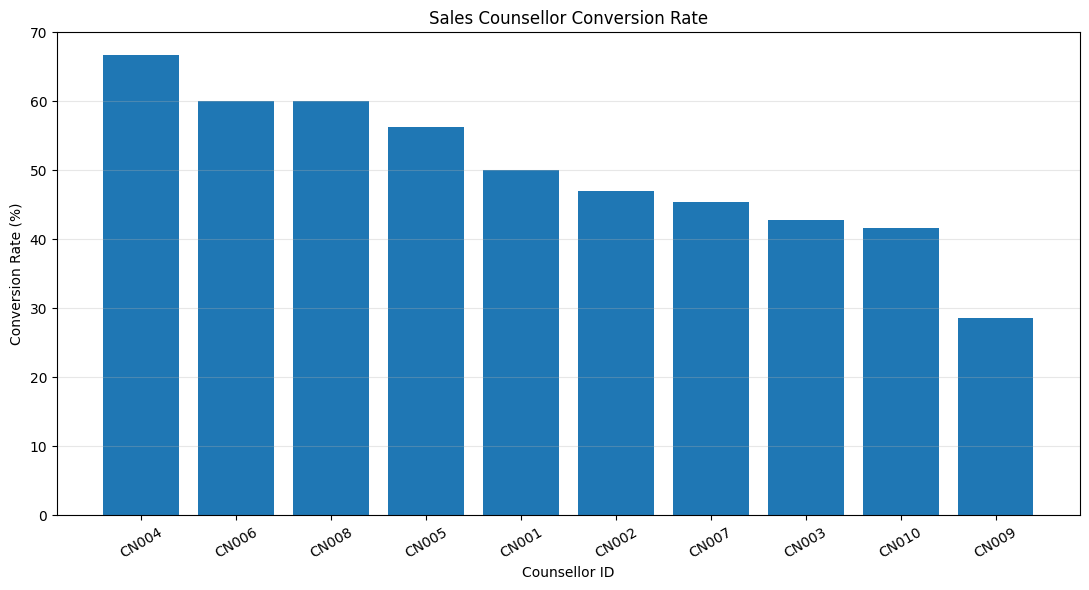

COUNSELLOR ANALYSIS COMPLETED!


In [14]:

# STEP 11: SALES COUNSELLOR PERFORMANCE

# Connect sales records with enrolments
counsellor_data = sales_df.merge(
    enrolment_df[["lead_id", "fee_paid", "refund"]],
    on="lead_id",
    how="left"
)

# Identify successful demos
counsellor_data["demo_flag"] = (
    counsellor_data["demo_attended"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["yes", "true", "1"])
)

# Identify enrolled students
counsellor_data["enrolled_flag"] = (
    counsellor_data["fee_paid"].notna()
)

# Group by counsellor
counsellor_analysis = counsellor_data.groupby(
    "counsellor_id"
).agg(
    leads_handled=("lead_id", "nunique"),
    total_calls=("call_attempts", "sum"),
    average_calls=("call_attempts", "mean"),
    demos_attended=("demo_flag", "sum"),
    enrolled_students=("enrolled_flag", "sum"),
    revenue=("fee_paid", "sum")
)

# Calculate performance metrics
counsellor_analysis["Demo_Rate"] = (
    counsellor_analysis["demos_attended"] /
    counsellor_analysis["leads_handled"]
) * 100

counsellor_analysis["Conversion_Rate"] = (
    counsellor_analysis["enrolled_students"] /
    counsellor_analysis["leads_handled"]
) * 100

# Rank by conversion rate
counsellor_analysis = counsellor_analysis.sort_values(
    by="Conversion_Rate",
    ascending=False
)

print("========== COUNSELLOR PERFORMANCE ==========")

display(counsellor_analysis.round(2))

# Plot conversion rate
plt.figure(figsize=(11, 6))

plt.bar(
    counsellor_analysis.index.astype(str),
    counsellor_analysis["Conversion_Rate"]
)

plt.title("Sales Counsellor Conversion Rate")
plt.xlabel("Counsellor ID")
plt.ylabel("Conversion Rate (%)")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("COUNSELLOR ANALYSIS COMPLETED!")


In [15]:

# STEP 12: CAMPAIGN PERFORMANCE ANALYSIS

# Aggregate advertising performance
campaign_spend = performance_df.groupby(
    "campaign_id"
).agg(
    total_spend=("spend", "sum"),
    total_clicks=("clicks", "sum"),
    total_impressions=("impressions", "sum")
)

# Count leads per campaign
campaign_leads = lead_df.groupby(
    "campaign_id"
).agg(
    total_leads=("lead_id", "nunique")
)

# Connect enrolments to campaigns
campaign_enrolments = enrolment_df.merge(
    lead_df[["lead_id", "campaign_id"]],
    on="lead_id",
    how="left"
)

campaign_sales = campaign_enrolments.groupby(
    "campaign_id"
).agg(
    total_enrolments=("lead_id", "nunique"),
    revenue=("fee_paid", "sum")
)

# Combine campaign results
campaign_analysis = (
    campaign_spend
    .join(campaign_leads)
    .join(campaign_sales)
    .fillna(0)
)

# Calculate campaign KPIs
campaign_analysis["CPL"] = (
    campaign_analysis["total_spend"] /
    campaign_analysis["total_leads"].replace(0, np.nan)
)

campaign_analysis["CAC"] = (
    campaign_analysis["total_spend"] /
    campaign_analysis["total_enrolments"].replace(0, np.nan)
)

campaign_analysis["Conversion_Rate"] = (
    campaign_analysis["total_enrolments"] /
    campaign_analysis["total_leads"].replace(0, np.nan)
) * 100

campaign_analysis["ROAS"] = (
    campaign_analysis["revenue"] /
    campaign_analysis["total_spend"].replace(0, np.nan)
)

# Rank campaigns by lead volume
campaign_analysis = campaign_analysis.sort_values(
    "total_leads",
    ascending=False
)

print("========== CAMPAIGN PERFORMANCE ==========")

display(campaign_analysis.round(2))

print("\nTOP 5 CAMPAIGNS BY LEADS")

display(
    campaign_analysis.head(5).round(2)
)

print("\nCAMPAIGNS WITH HIGH LEADS BUT LOW ENROLMENTS")

display(
    campaign_analysis[
        (campaign_analysis["total_leads"] >= 2) &
        (campaign_analysis["Conversion_Rate"] < 30)
    ].round(2)
)

print("\nCAMPAIGN ANALYSIS COMPLETED!")


========== CAMPAIGN PERFORMANCE ==========


,total_spend,total_clicks,total_impressions,total_leads,total_enrolments,revenue,CPL,CAC,Conversion_Rate,ROAS
campaign_id,,,,,,,,,,
CMP089,2197.82,334,27191,5.0,3.0,111460.72,439.56,732.61,60.00,50.71
CMP095,596.33,1561,14126,4.0,2.0,72271.66,149.08,298.17,50.00,121.19
CMP031,1467.13,1187,12269,3.0,2.0,64658.17,489.04,733.56,66.67,44.07
CMP032,1043.41,1137,10841,3.0,2.0,66952.50,347.80,521.71,66.67,64.17
CMP058,2388.99,3159,20783,3.0,2.0,43514.07,796.33,1194.49,66.67,18.21
...,...,...,...,...,...,...,...,...,...,...
CMP088,2276.39,312,4401,0.0,0.0,0.00,NaN,NaN,NaN,0.00
CMP085,1796.75,909,8919,0.0,0.0,0.00,NaN,NaN,NaN,0.00
CMP096,186.18,1909,10948,0.0,0.0,0.00,NaN,NaN,NaN,0.00



TOP 5 CAMPAIGNS BY LEADS


,total_spend,total_clicks,total_impressions,total_leads,total_enrolments,revenue,CPL,CAC,Conversion_Rate,ROAS
campaign_id,,,,,,,,,,
CMP089,2197.82,334,27191,5.0,3.0,111460.72,439.56,732.61,60.00,50.71
CMP095,596.33,1561,14126,4.0,2.0,72271.66,149.08,298.17,50.00,121.19
CMP031,1467.13,1187,12269,3.0,2.0,64658.17,489.04,733.56,66.67,44.07
CMP032,1043.41,1137,10841,3.0,2.0,66952.50,347.80,521.71,66.67,64.17
CMP058,2388.99,3159,20783,3.0,2.0,43514.07,796.33,1194.49,66.67,18.21



CAMPAIGNS WITH HIGH LEADS BUT LOW ENROLMENTS


,total_spend,total_clicks,total_impressions,total_leads,total_enrolments,revenue,CPL,CAC,Conversion_Rate,ROAS
campaign_id,,,,,,,,,,
CMP019,1804.00,217,5441,3.0,0.0,0.0,601.33,NaN,0.0,0.0
CMP003,422.43,213,5271,2.0,0.0,0.0,211.22,NaN,0.0,0.0
CMP010,1327.73,684,11220,2.0,0.0,0.0,663.86,NaN,0.0,0.0
CMP074,171.79,1129,18478,2.0,0.0,0.0,85.90,NaN,0.0,0.0
CMP042,523.92,4587,23709,2.0,0.0,0.0,261.96,NaN,0.0,0.0



CAMPAIGN ANALYSIS COMPLETED!


In [16]:

# STEP 13: IDENTIFY UNDERPERFORMING CAMPAIGNS

# Campaigns that spent money but generated zero leads
zero_lead_campaigns = campaign_analysis[
    (campaign_analysis["total_spend"] > 0) &
    (campaign_analysis["total_leads"] == 0)
].sort_values(
    "total_spend",
    ascending=False
)

print("CAMPAIGNS WITH SPEND BUT ZERO LEADS")

display(
    zero_lead_campaigns[
        ["total_spend", "total_clicks", "total_impressions"]
    ].head(15).round(2)
)

# Campaigns with leads but poor conversion
low_conversion_campaigns = campaign_analysis[
    (campaign_analysis["total_leads"] >= 2) &
    (campaign_analysis["Conversion_Rate"] < 30)
].sort_values(
    "total_spend",
    ascending=False
)

print("\nCAMPAIGNS WITH LOW ENROLMENT CONVERSION")

display(
    low_conversion_campaigns[
        ["total_spend", "total_leads",
         "total_enrolments", "Conversion_Rate", "CAC"]
    ].head(15).round(2)
)

print("\nUNDERPERFORMING CAMPAIGN ANALYSIS COMPLETED!")


CAMPAIGNS WITH SPEND BUT ZERO LEADS


,total_spend,total_clicks,total_impressions
campaign_id,,,
CMP100,2494.01,1275,8238
CMP014,2336.61,3595,20037
CMP015,2325.69,3246,17272
CMP088,2276.39,312,4401
CMP050,2262.69,4950,29919
CMP047,2244.51,2969,21414
CMP098,2191.82,1097,10354
CMP021,1986.50,1637,10661
CMP091,1916.10,2150,16602



CAMPAIGNS WITH LOW ENROLMENT CONVERSION


,total_spend,total_leads,total_enrolments,Conversion_Rate,CAC
campaign_id,,,,,
CMP019,1804.00,3.0,0.0,0.0,NaN
CMP010,1327.73,2.0,0.0,0.0,NaN
CMP042,523.92,2.0,0.0,0.0,NaN
CMP003,422.43,2.0,0.0,0.0,NaN
CMP074,171.79,2.0,0.0,0.0,NaN



UNDERPERFORMING CAMPAIGN ANALYSIS COMPLETED!


===== LEADS BY CITY =====


,total_leads
city,
Guntur,15
Parvathipuram,15
Srikakulam,14
Rajahmundry,13
Tirupati,11
Vijayawada,11
Visakhapatnam,11
Vizianagaram,10



===== LEADS BY AGE GROUP =====


,total_leads
age_group,
26-30,22
18-20,21
31-35,21
36+,21
21-25,15



===== LEADS BY COURSE INTEREST =====


,total_leads
course_interest,
Full Stack Development,24
Python Programming,23
Digital Marketing,21
Data Analytics,16
Web Development,16


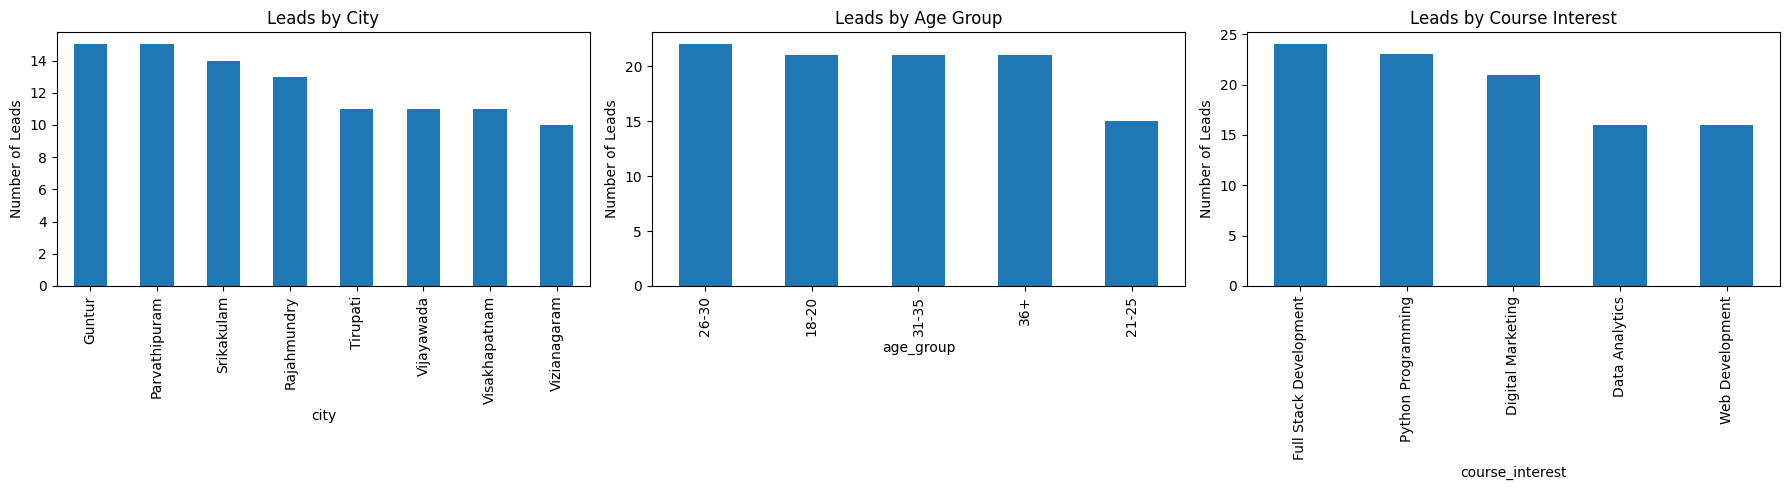

AUDIENCE ANALYSIS COMPLETED!


In [17]:

# STEP 14: AUDIENCE ANALYSIS

# Analyze cities
city_analysis = lead_df.groupby("city").agg(
    total_leads=("lead_id", "nunique")
).sort_values("total_leads", ascending=False)

print("===== LEADS BY CITY =====")
display(city_analysis)

# Analyze age groups
age_analysis = lead_df.groupby("age_group").agg(
    total_leads=("lead_id", "nunique")
).sort_values("total_leads", ascending=False)

print("\n===== LEADS BY AGE GROUP =====")
display(age_analysis)

# Analyze course interests
interest_analysis = lead_df.groupby("course_interest").agg(
    total_leads=("lead_id", "nunique")
).sort_values("total_leads", ascending=False)

print("\n===== LEADS BY COURSE INTEREST =====")
display(interest_analysis)

# Visualize audience analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

city_analysis.plot(kind="bar", ax=axes[0], legend=False)
axes[0].set_title("Leads by City")
axes[0].set_ylabel("Number of Leads")

age_analysis.plot(kind="bar", ax=axes[1], legend=False)
axes[1].set_title("Leads by Age Group")
axes[1].set_ylabel("Number of Leads")

interest_analysis.plot(kind="bar", ax=axes[2], legend=False)
axes[2].set_title("Leads by Course Interest")
axes[2].set_ylabel("Number of Leads")

plt.tight_layout()
plt.show()

print("AUDIENCE ANALYSIS COMPLETED!")


In [18]:

# STEP 15: ACTUAL AUDIENCE CONVERSION

enrolled_ids = set(enrolment_df["lead_id"])

audience_df = lead_df.copy()

audience_df["enrolled"] = (
    audience_df["lead_id"].isin(enrolled_ids).astype(int)
)

for col in ["city", "age_group", "course_interest"]:

    result = audience_df.groupby(col).agg(
        Leads=("lead_id", "nunique"),
        Enrolments=("enrolled", "sum")
    )

    result["Conversion Rate (%)"] = (
        result["Enrolments"] / result["Leads"] * 100
    ).round(2)

    print("\nCONVERSION ANALYSIS:", col.upper())

    display(
        result.sort_values(
            "Conversion Rate (%)",
            ascending=False
        )
    )

print("AUDIENCE CONVERSION ANALYSIS COMPLETED!")



CONVERSION ANALYSIS: CITY


,Leads,Enrolments,Conversion Rate (%)
city,,,
Vizianagaram,10,8,80.00
Visakhapatnam,11,7,63.64
Srikakulam,14,8,57.14
Guntur,15,8,53.33
Parvathipuram,15,7,46.67
Vijayawada,11,5,45.45
Tirupati,11,5,45.45
Rajahmundry,13,2,15.38



CONVERSION ANALYSIS: AGE_GROUP


,Leads,Enrolments,Conversion Rate (%)
age_group,,,
21-25,15,9,60.00
36+,21,12,57.14
31-35,21,11,52.38
18-20,21,10,47.62
26-30,22,8,36.36



CONVERSION ANALYSIS: COURSE_INTEREST


,Leads,Enrolments,Conversion Rate (%)
course_interest,,,
Digital Marketing,21,12,57.14
Data Analytics,16,9,56.25
Full Stack Development,24,13,54.17
Python Programming,23,11,47.83
Web Development,16,5,31.25


AUDIENCE CONVERSION ANALYSIS COMPLETED!


In [19]:

# STEP 16: EXPORT CLEANED DATA AND REPORTS

import os
import zipfile
import pandas as pd

output_folder = "/content/LearnSphere_Final_Reports"

os.makedirs(output_folder, exist_ok=True)

# Export all five cleaned datasets
datasets = {
    "Campaign": campaign_df,
    "Performance": performance_df,
    "Leads": lead_df,
    "Sales": sales_df,
    "Enrolments": enrolment_df
}

for name, df in datasets.items():
    df.to_csv(
        f"{output_folder}/{name}.csv",
        index=False
    )

# Export audience conversion reports
for col in ["city", "age_group", "course_interest"]:

    report = audience_df.groupby(col).agg(
        Leads=("lead_id", "nunique"),
        Enrolments=("enrolled", "sum")
    )

    report["Conversion_Rate"] = (
        report["Enrolments"] /
        report["Leads"] * 100
    ).round(2)

    report.to_csv(
        f"{output_folder}/{col}_analysis.csv"
    )

# Create ZIP file
zip_path = "/content/LearnSphere_Final_Reports.zip"

with zipfile.ZipFile(zip_path, "w") as z:
    for file in os.listdir(output_folder):
        z.write(
            f"{output_folder}/{file}",
            arcname=file
        )

print("ALL REPORTS EXPORTED SUCCESSFULLY!")
print("Files created:", len(os.listdir(output_folder)))
print("ZIP:", zip_path)

from google.colab import files
files.download(zip_path)


ALL REPORTS EXPORTED SUCCESSFULLY!
Files created: 8
ZIP: /content/LearnSphere_Final_Reports.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>